# Assignment 3 - Insurance Risk Prediction Models
## Notebook 1: Regression (predicting individual medical insurance expenses)

**Course:** Data Science Advanced Programming (IBM)
**Dataset:** `med-insurance.csv` (1,338 policyholders; age, sex, BMI, children, smoker, region, expenses)
**Target:** `expenses` - yearly medical cost charged to the insurer (continuous)

**Workflow:** EDA -> preprocessing -> Linear / Ridge / Lasso / Elastic Net / Random Forest / XGBoost -> tuning with 5-fold cross-validation -> MAE, RMSE, R2, Adjusted R2 -> SHAP explainability.

## 1. Setup and data loading

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
FIG = 'figs/'

df = pd.read_csv('med-insurance.csv')
print('Raw shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)   # one exact duplicate record is removed
print('Shape after removing duplicates:', df.shape)
df.head()

Raw shape: (1338, 7)
Duplicate rows: 1
Shape after removing duplicates: (1337, 7)


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [2]:
print(df.dtypes)
print('\nMissing values per column:\n', df.isna().sum())
df.describe().round(2)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
expenses    float64
dtype: object

Missing values per column:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64


,age,bmi,children,expenses
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.67,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,16.00,0.00,1121.87
25%,27.00,26.30,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.10,5.00,63770.43


## 2. Exploratory Data Analysis (EDA)
Domain note: *expenses* is the cost the insurer pays out for a person, so the target is a **claim-cost / premium proxy**. Insurance costs are typically right-skewed (many cheap customers, a few extremely expensive ones).

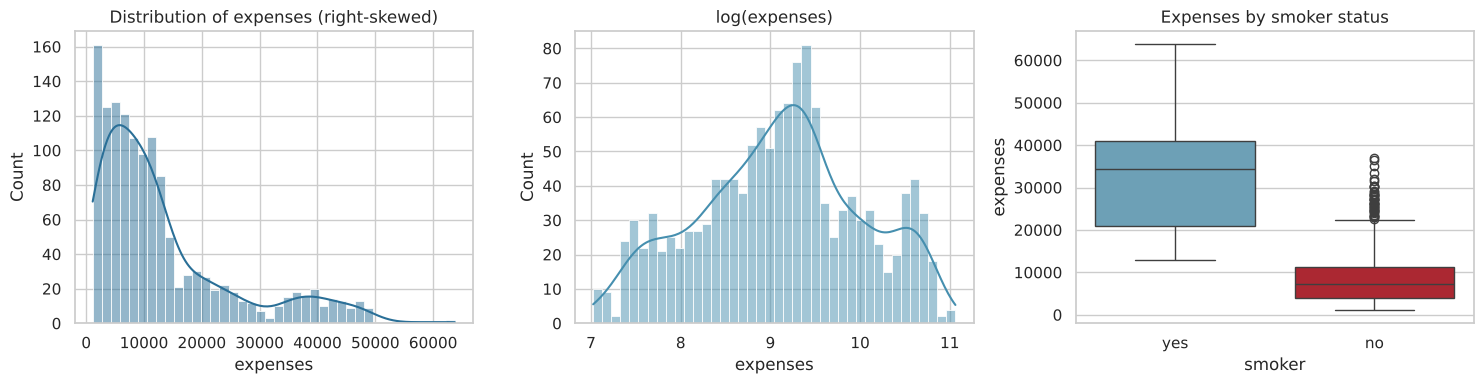

Skewness of expenses: 1.52
        count     mean   median
smoker                         
no       1063   8441.0   7346.0
yes       274  32050.0  34456.0


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['expenses'], bins=40, kde=True, ax=ax[0], color='#2a6f97')
ax[0].set_title('Distribution of expenses (right-skewed)')
sns.histplot(np.log1p(df['expenses']), bins=40, kde=True, ax=ax[1], color='#468faf')
ax[1].set_title('log(expenses)')
sns.boxplot(data=df, x='smoker', y='expenses', ax=ax[2], palette=['#61a5c2', '#c1121f'])
ax[2].set_title('Expenses by smoker status')
plt.tight_layout(); plt.savefig(FIG + 'reg_eda_target.png', dpi=160); plt.show()
print('Skewness of expenses:', round(df['expenses'].skew(), 2))
print(df.groupby('smoker')['expenses'].agg(['count', 'mean', 'median']).round(0))

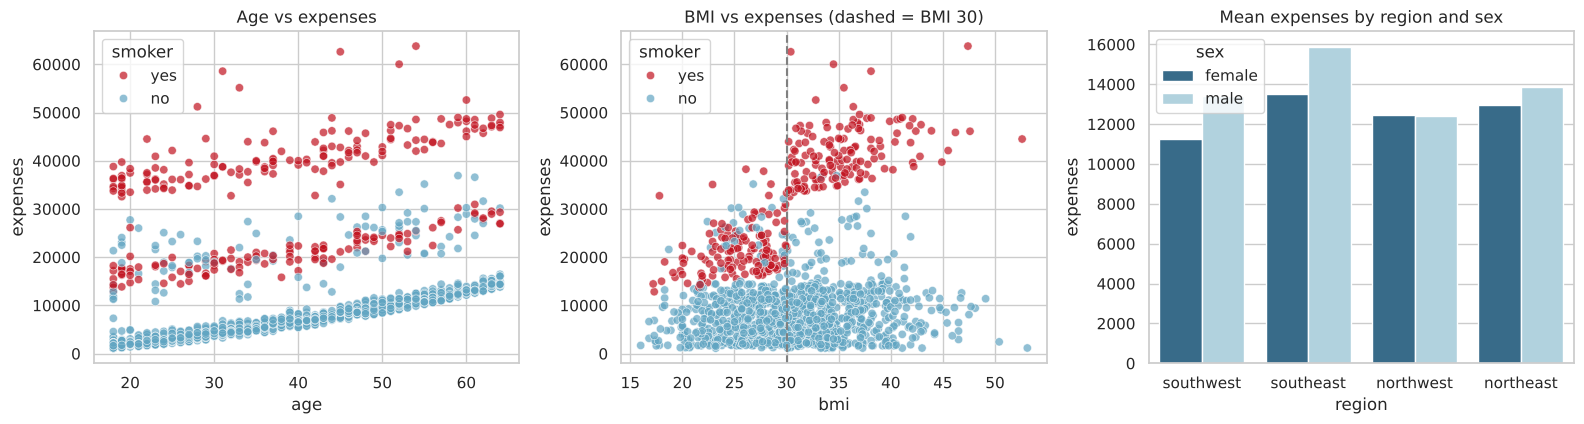

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
sns.scatterplot(data=df, x='age', y='expenses', hue='smoker', palette={'no': '#61a5c2', 'yes': '#c1121f'}, alpha=.7, ax=ax[0])
ax[0].set_title('Age vs expenses')
sns.scatterplot(data=df, x='bmi', y='expenses', hue='smoker', palette={'no': '#61a5c2', 'yes': '#c1121f'}, alpha=.7, ax=ax[1])
ax[1].axvline(30, ls='--', c='grey'); ax[1].set_title('BMI vs expenses (dashed = BMI 30)')
sns.barplot(data=df, x='region', y='expenses', hue='sex', errorbar=None, ax=ax[2], palette=['#2a6f97', '#a9d6e5'])
ax[2].set_title('Mean expenses by region and sex')
plt.tight_layout(); plt.savefig(FIG + 'reg_eda_relations.png', dpi=160); plt.show()

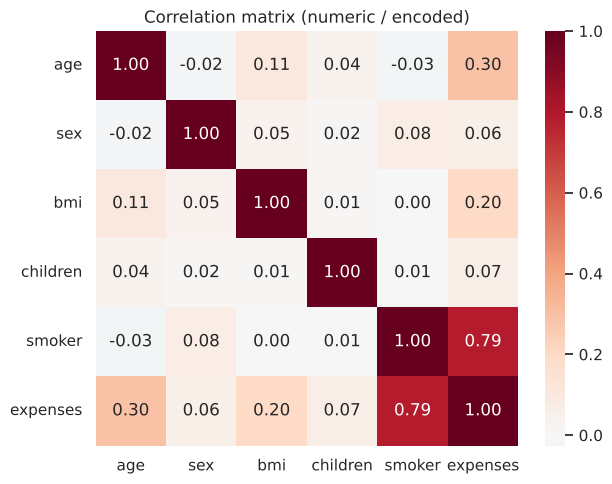

expenses    1.000
smoker      0.787
age         0.298
bmi         0.199
children    0.067
sex         0.058
Name: expenses, dtype: float64

Expenses above the IQR upper fence: 139 rows (10.4%) - kept, because large claims are real insurance events.


In [5]:
enc = df.copy()
enc['sex'] = (enc['sex'] == 'male').astype(int)
enc['smoker'] = (enc['smoker'] == 'yes').astype(int)
corr = enc.drop(columns='region').corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation matrix (numeric / encoded)')
plt.tight_layout(); plt.savefig(FIG + 'reg_corr.png', dpi=160); plt.show()
print(corr['expenses'].sort_values(ascending=False).round(3))

# Outlier check using the IQR rule
q1, q3 = df['expenses'].quantile([.25, .75]); iqr = q3 - q1
n_out = (df['expenses'] > q3 + 1.5 * iqr).sum()
print(f'\nExpenses above the IQR upper fence: {n_out} rows ({n_out/len(df):.1%}) - kept, because large claims are real insurance events.')

**EDA findings (used later in the report)**
1. Expenses are strongly right-skewed (long tail of very expensive customers) - this is why RMSE matters.
2. `smoker` is by far the strongest driver; smokers cost several times more than non-smokers.
3. `age` raises costs steadily; `bmi` matters mostly for obese (BMI >= 30) *smokers* - an interaction effect that linear models cannot see without help.
4. `sex`, `region` and `children` show weak relationships with cost.
5. No missing values; one duplicate row removed.

## 3. Preprocessing
* Train / test split 80 / 20, **stratified by smoker** so both sets contain the same smoker share.
* One-hot encode `sex`, `smoker`, `region` (drop first level to avoid the dummy-variable trap).
* **Linear models:** numeric features are standardised (required for Ridge / Lasso / Elastic Net, whose penalties depend on coefficient size).
* **Tree models:** no scaling needed (and unscaled values keep SHAP plots readable).
* Preprocessing lives inside sklearn `Pipeline`s so the scaler/encoder is fitted on training folds only (no data leakage).

In [6]:
X = df.drop(columns='expenses')
y = df['expenses']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=X['smoker'])
print('Train:', X_train.shape, ' Test:', X_test.shape)

num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

pre_lin = ColumnTransformer([('num', StandardScaler(), num_cols),
                             ('cat', OneHotEncoder(drop='first'), cat_cols)])
pre_tree = ColumnTransformer([('num', 'passthrough', num_cols),
                              ('cat', OneHotEncoder(drop='first'), cat_cols)])
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (1069, 6)  Test: (268, 6)


## 4. Models, hyperparameter tuning and 5-fold cross-validation
Each model is tuned with `GridSearchCV` (5-fold CV, scoring = negative RMSE) on the **training set only**.

In [7]:
def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate(name, model, Xte, yte, n_features):
    pred = model.predict(Xte)
    mae = mean_absolute_error(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    r2 = r2_score(yte, pred)
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'Adj_R2': adj_r2(r2, len(yte), n_features)}, pred

specs = {
    'Linear Regression': (Pipeline([('pre', pre_lin), ('m', LinearRegression())]), {}),
    'Ridge (L2)': (Pipeline([('pre', pre_lin), ('m', Ridge())]),
                   {'m__alpha': [0.01, 0.1, 1, 10, 50, 100]}),
    'Lasso (L1)': (Pipeline([('pre', pre_lin), ('m', Lasso(max_iter=50000))]),
                   {'m__alpha': [0.1, 1, 10, 50, 100, 300]}),
    'Elastic Net': (Pipeline([('pre', pre_lin), ('m', ElasticNet(max_iter=50000))]),
                    {'m__alpha': [0.01, 0.1, 1, 10], 'm__l1_ratio': [0.2, 0.5, 0.8]}),
    'Random Forest': (Pipeline([('pre', pre_tree), ('m', RandomForestRegressor(random_state=SEED, n_jobs=-1))]),
                      {'m__n_estimators': [200, 400], 'm__max_depth': [4, 6, 8, None],
                       'm__min_samples_leaf': [3, 5, 10], 'm__max_features': [0.6, 1.0]}),
    'XGBoost': (Pipeline([('pre', pre_tree), ('m', XGBRegressor(random_state=SEED, n_jobs=4, objective='reg:squarederror'))]),
                {'m__n_estimators': [100, 200, 400], 'm__max_depth': [2, 3, 4],
                 'm__learning_rate': [0.02, 0.05, 0.1], 'm__subsample': [0.8, 1.0]}),
}
n_feat = pre_lin.fit(X_train).transform(X_train).shape[1]
print('Number of model features after encoding:', n_feat)

fitted, rows, preds, cv_rows, best_params = {}, [], {}, [], {}
for name, (pipe, grid) in specs.items():
    if grid:
        gs = GridSearchCV(pipe, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
        gs.fit(X_train, y_train)
        best = gs.best_estimator_; best_params[name] = {k.replace('m__', ''): v for k, v in gs.best_params_.items()}
    else:
        best = pipe.fit(X_train, y_train); best_params[name] = {}
    cvs = -cross_val_score(best, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    row, pred = evaluate(name, best, X_test, y_test, n_feat)
    row['CV_RMSE_mean'], row['CV_RMSE_std'] = cvs.mean(), cvs.std()
    rows.append(row); fitted[name] = best; preds[name] = pred
    print(f'{name:18s} CV RMSE {cvs.mean():9.1f} (+/- {cvs.std():6.1f})  | Test RMSE {row["RMSE"]:9.1f}  R2 {row["R2"]:.3f}  params {best_params[name]}')

Number of model features after encoding: 8
Linear Regression  CV RMSE    6297.0 (+/-  628.8)  | Test RMSE    5086.1  R2 0.821  params {}


Ridge (L2)         CV RMSE    6297.0 (+/-  629.2)  | Test RMSE    5086.3  R2 0.821  params {'alpha': 0.1}


Lasso (L1)         CV RMSE    6297.0 (+/-  629.0)  | Test RMSE    5085.8  R2 0.821  params {'alpha': 1}


Elastic Net        CV RMSE    6297.6 (+/-  634.9)  | Test RMSE    5091.6  R2 0.820  params {'alpha': 0.01, 'l1_ratio': 0.8}


Random Forest      CV RMSE    4748.9 (+/-  612.1)  | Test RMSE    3400.0  R2 0.920  params {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 400}


XGBoost            CV RMSE    4721.9 (+/-  647.7)  | Test RMSE    3364.0  R2 0.922  params {'learning_rate': 0.02, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}


## 5. Model comparison table
Metrics are computed on the **held-out test set** (268 unseen customers). `CV_RMSE` comes from 5-fold cross-validation on the training data and shows how stable each model is.

,MAE,RMSE,R2,Adj_R2,CV_RMSE_mean,CV_RMSE_std
Model,,,,,,
Linear Regression,3591.962,5086.145,0.821,0.815,6297.049,628.812
Ridge (L2),3592.938,5086.340,0.821,0.815,6297.015,629.164
Lasso (L1),3592.195,5085.791,0.821,0.815,6297.044,629.001
Elastic Net,3613.856,5091.608,0.820,0.815,6297.563,634.852
Random Forest,2178.259,3399.975,0.920,0.917,4748.877,612.084
XGBoost,2120.387,3363.955,0.922,0.919,4721.912,647.748


Best model by test RMSE: XGBoost


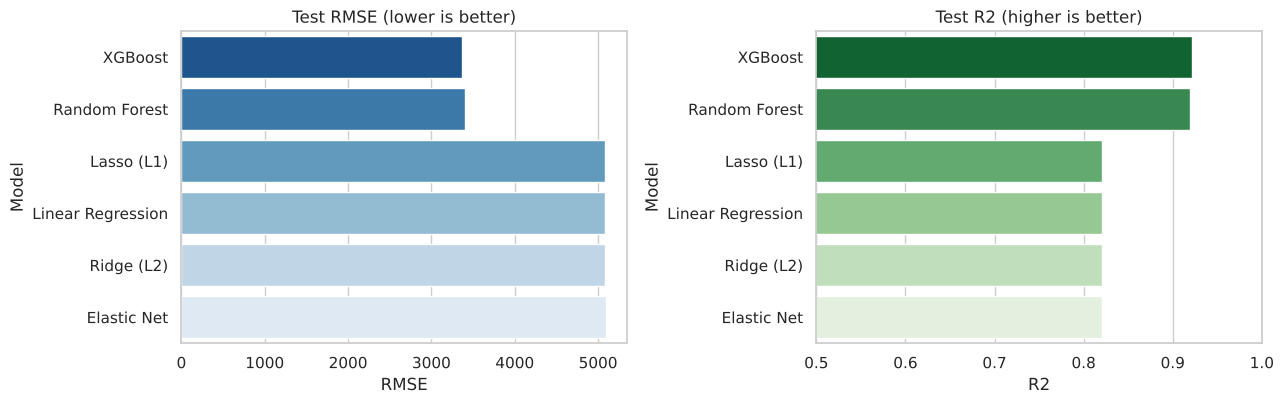

In [8]:
res = pd.DataFrame(rows).set_index('Model')
res = res[['MAE', 'RMSE', 'R2', 'Adj_R2', 'CV_RMSE_mean', 'CV_RMSE_std']]
display(res.round(3))
res.to_csv('results/regression_comparison.csv')
best_name = res['RMSE'].idxmin()
print('Best model by test RMSE:', best_name)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
order = res.sort_values('RMSE').index
sns.barplot(x=res.loc[order, 'RMSE'], y=order, ax=ax[0], palette='Blues_r'); ax[0].set_title('Test RMSE (lower is better)')
sns.barplot(x=res.loc[order, 'R2'], y=order, ax=ax[1], palette='Greens_r'); ax[1].set_title('Test R2 (higher is better)')
ax[1].set_xlim(0.5, 1)
plt.tight_layout(); plt.savefig(FIG + 'reg_model_comparison.png', dpi=160); plt.show()

### 5.1 Extra experiment - can feature engineering rescue the linear model?
EDA showed that obesity (BMI >= 30) combined with smoking is expensive. We add two engineered features and refit plain linear regression to see how much of the gap to the tree models is simply a missing interaction.

In [9]:
def add_feats(d):
    d = d.copy()
    d['obese'] = (d['bmi'] >= 30).astype(int)
    d['smoker_obese'] = ((d['smoker'] == 'yes') & (d['bmi'] >= 30)).astype(int)
    return d

pre_eng = ColumnTransformer([('num', StandardScaler(), num_cols),
                             ('bin', 'passthrough', ['obese', 'smoker_obese']),
                             ('cat', OneHotEncoder(drop='first'), cat_cols)])
lin_eng = Pipeline([('pre', pre_eng), ('m', LinearRegression())]).fit(add_feats(X_train), y_train)
row_eng, pred_eng = evaluate('Linear + interaction', lin_eng, add_feats(X_test), y_test, n_feat + 2)
print(pd.DataFrame([row_eng]).set_index('Model').round(3))
res_eng = row_eng

                           MAE      RMSE     R2  Adj_R2
Model                                                  
Linear + interaction  2139.864  3439.637  0.918   0.915


## 6. Diagnostics of the best model

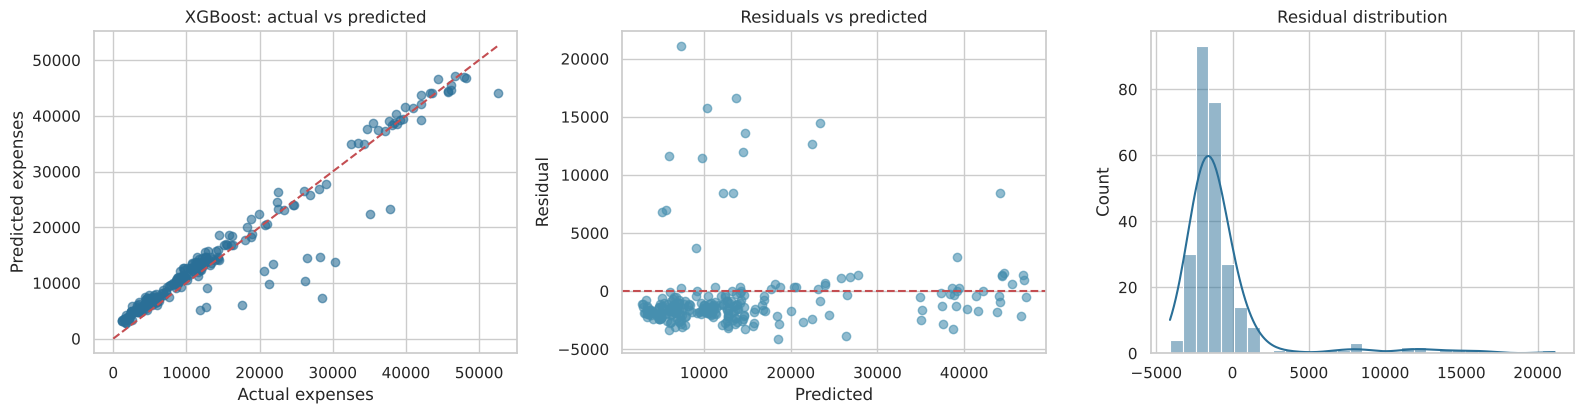

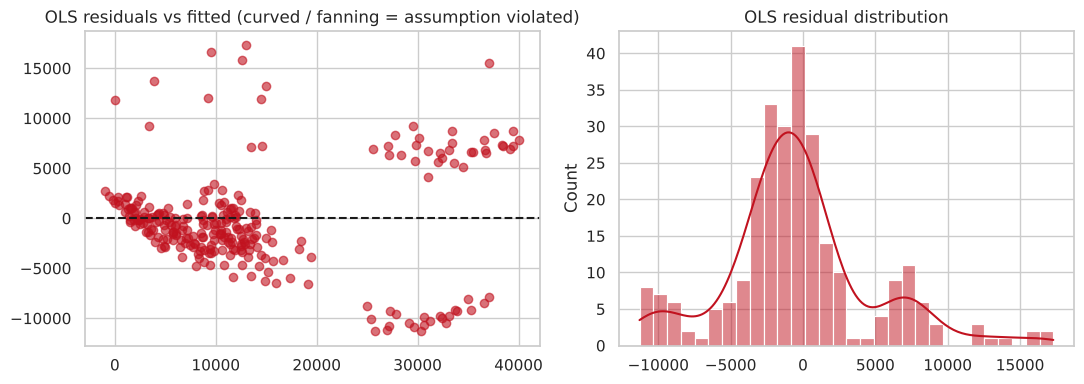

,Linear,Ridge,Lasso,ElasticNet
num__age,3594.1,3593.6,3593.2,3583.9
num__bmi,2012.9,2012.5,2010.7,2003.9
num__children,740.0,740.0,738.9,739.6
cat__sex_male,-257.9,-257.2,-253.6,-242.9
cat__smoker_yes,23749.8,23735.9,23743.0,23457.2
cat__region_northwest,-361.0,-360.1,-344.6,-341.8
cat__region_southeast,-1193.9,-1191.5,-1176.2,-1143.5
cat__region_southwest,-1030.9,-1029.8,-1014.1,-1006.9


In [10]:
bp = preds[best_name]
resid = y_test.values - bp
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].scatter(y_test, bp, alpha=.6, c='#2a6f97'); lim = [0, max(y_test.max(), bp.max())]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Actual expenses'); ax[0].set_ylabel('Predicted expenses'); ax[0].set_title(f'{best_name}: actual vs predicted')
ax[1].scatter(bp, resid, alpha=.6, c='#468faf'); ax[1].axhline(0, c='r', ls='--')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residuals vs predicted')
sns.histplot(resid, bins=30, kde=True, ax=ax[2], color='#2a6f97'); ax[2].set_title('Residual distribution')
plt.tight_layout(); plt.savefig(FIG + 'reg_diagnostics.png', dpi=160); plt.show()

# Linear-model assumption check on plain OLS residuals
ols_resid = y_test.values - preds['Linear Regression']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(preds['Linear Regression'], ols_resid, alpha=.6, c='#c1121f'); ax[0].axhline(0, c='k', ls='--')
ax[0].set_title('OLS residuals vs fitted (curved / fanning = assumption violated)')
sns.histplot(ols_resid, bins=30, kde=True, ax=ax[1], color='#c1121f'); ax[1].set_title('OLS residual distribution')
plt.tight_layout(); plt.savefig(FIG + 'reg_ols_assumptions.png', dpi=160); plt.show()

# Coefficients: Ridge vs Lasso (Lasso zeroes weak features)
names = fitted['Linear Regression'].named_steps['pre'].get_feature_names_out()
coef = pd.DataFrame({'Linear': fitted['Linear Regression'].named_steps['m'].coef_,
                     'Ridge': fitted['Ridge (L2)'].named_steps['m'].coef_,
                     'Lasso': fitted['Lasso (L1)'].named_steps['m'].coef_,
                     'ElasticNet': fitted['Elastic Net'].named_steps['m'].coef_}, index=names).round(1)
display(coef)
coef.to_csv('results/regression_coefficients.csv')

## 7. Explainability with SHAP (mandatory)
SHAP assigns each feature a contribution to each individual prediction - this is how an insurer can justify to a customer or regulator *why* a given price was produced. We explain the best **tree-based** model.

Explaining: XGBoost


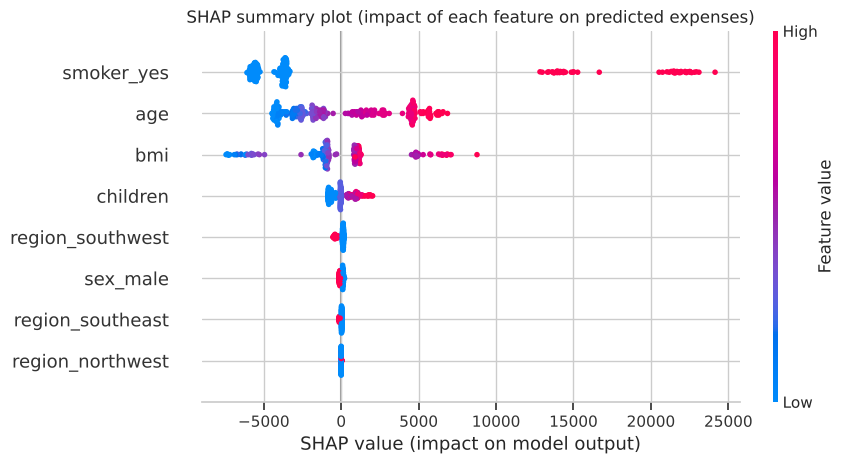

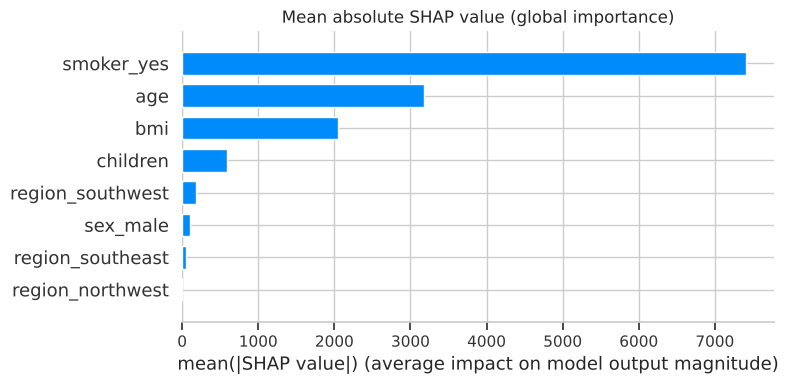

,mean |SHAP| (USD)
smoker_yes,7406.899902
age,3181.100098
bmi,2048.699951
children,595.000000
region_southwest,188.100006
sex_male,102.199997
region_southeast,49.700001
region_northwest,3.800000


In [11]:
tree_names = ['Random Forest', 'XGBoost']
shap_name = min(tree_names, key=lambda n: res.loc[n, 'RMSE'])
print('Explaining:', shap_name)
pipe = fitted[shap_name]
Xte_t = pipe.named_steps['pre'].transform(X_test)
fnames = [n.split('__')[1] for n in pipe.named_steps['pre'].get_feature_names_out()]
Xte_df = pd.DataFrame(Xte_t, columns=fnames)
explainer = shap.TreeExplainer(pipe.named_steps['m'])
sv = explainer(Xte_df)

plt.figure()
shap.summary_plot(sv.values, Xte_df, show=False, plot_size=(9, 4.8))
plt.title('SHAP summary plot (impact of each feature on predicted expenses)')
plt.tight_layout(); plt.savefig(FIG + 'reg_shap_summary.png', dpi=160, bbox_inches='tight'); plt.show()

plt.figure()
shap.summary_plot(sv.values, Xte_df, plot_type='bar', show=False, plot_size=(8, 4))
plt.title('Mean absolute SHAP value (global importance)')
plt.tight_layout(); plt.savefig(FIG + 'reg_shap_bar.png', dpi=160, bbox_inches='tight'); plt.show()

imp = pd.Series(np.abs(sv.values).mean(0), index=fnames).sort_values(ascending=False)
display(imp.round(1).to_frame('mean |SHAP| (USD)'))

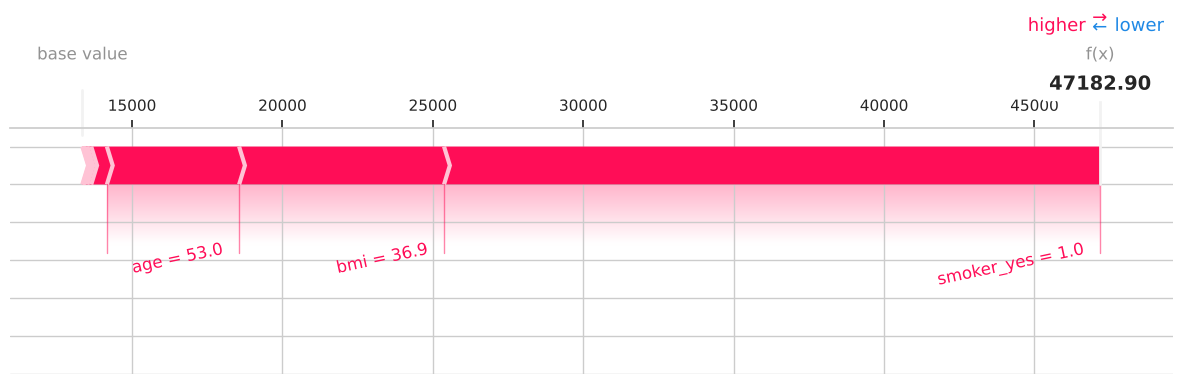

HIGH customer: {'age': 53, 'sex': 'female', 'bmi': 36.9, 'children': 3, 'smoker': 'yes', 'region': 'northwest'} | actual: 46661.0 | predicted: 47183.0


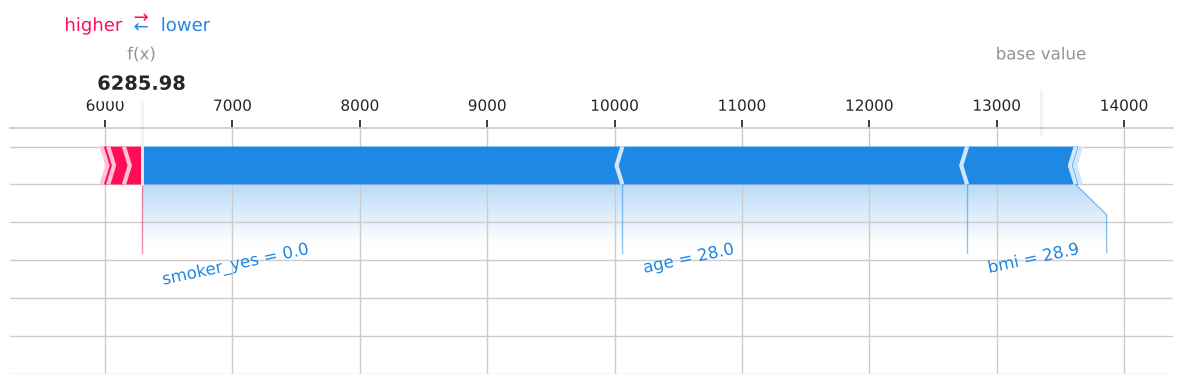

LOW customer: {'age': 28, 'sex': 'female', 'bmi': 28.9, 'children': 1, 'smoker': 'no', 'region': 'northeast'} | actual: 4338.0 | predicted: 6286.0


In [12]:
# Force plot for ONE customer: pick the highest-predicted customer and a typical low-cost customer
pred_t = pipe.predict(X_test)
i_high = int(np.argmax(pred_t)); i_low = int(np.argsort(pred_t)[len(pred_t) // 4])
for tag, i in [('high', i_high), ('low', i_low)]:
    shap.force_plot(sv.base_values[i], sv.values[i], Xte_df.iloc[i], matplotlib=True, show=False, figsize=(15, 3.2), text_rotation=12)
    plt.savefig(FIG + f'reg_shap_force_{tag}.png', dpi=160, bbox_inches='tight'); plt.show()
    print(tag.upper(), 'customer:', X_test.iloc[i].to_dict(), '| actual:', round(float(y_test.iloc[i]), 0), '| predicted:', round(float(pred_t[i]), 0))
force_info = {'high': {'features': X_test.iloc[i_high].to_dict(), 'actual': float(y_test.iloc[i_high]), 'pred': float(pred_t[i_high])},
              'low': {'features': X_test.iloc[i_low].to_dict(), 'actual': float(y_test.iloc[i_low]), 'pred': float(pred_t[i_low])}}

## 8. Business interpretation
* **MAE** = average absolute miss in dollars - easy to explain to management.
* **RMSE** squares errors first, so one huge mis-priced claim hurts a lot - the metric an insurer cares about because large unexpected losses are what threaten solvency.
* **R2 / Adjusted R2** show how much of the cost variation the model explains; Adjusted R2 penalises useless variables.
* Tree ensembles beat the linear family because insurance cost is non-linear (smoker x BMI x age interactions).

In [13]:
out = {
    'n_rows': int(len(df)), 'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'n_features': int(n_feat),
    'comparison': res.reset_index().to_dict(orient='records'),
    'linear_interaction': res_eng,
    'best_model': best_name, 'shap_model': shap_name,
    'best_params': {k: {kk: (vv if not hasattr(vv, 'item') else vv.item()) for kk, vv in v.items()} for k, v in best_params.items()},
    'shap_importance': imp.round(2).to_dict(),
    'force': force_info,
    'target_stats': {'mean': float(y.mean()), 'median': float(y.median()), 'std': float(y.std()), 'skew': float(y.skew()),
                     'smoker_mean': float(df[df.smoker == 'yes'].expenses.mean()), 'nonsmoker_mean': float(df[df.smoker == 'no'].expenses.mean()),
                     'smoker_share': float((df.smoker == 'yes').mean())},
}
json.dump(out, open('results/regression_results.json', 'w'), indent=2, default=float)
print('Saved results/regression_results.json')

Saved results/regression_results.json
